In [50]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.efficientnet import preprocess_input


In [51]:
img_hgt = 224
img_wdt = 224
class_names = ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']

In [52]:
import tensorflow as tf

class FixedDense(tf.keras.layers.Dense):
    def __init__(self, *args, **kwargs):
        kwargs.pop('quantization_config', None)
        super().__init__(*args, **kwargs)

try:
    model = tf.keras.models.load_model(
        '../Model/effnet_0.82.h5',
        compile=False,
        # Map the standard name 'Dense' to your fixed class
        custom_objects={'Dense': FixedDense} 
    )
    print("Model loaded successfully!")
except Exception as e:
    print(f"Error loading model: {e}")

Model loaded successfully!


Found 11 image(s) in '../Test'

[1/11] Bird (4).jpg -> Bird-drop (64.15%)
[2/11] bird-drop.jpg -> Bird-drop (93.85%)
[3/11] Dust (5).jpg -> Dusty (97.57%)
[4/11] Dusty-Solar-Model-1.jpg -> Clean (95.75%)
[5/11] Dusty-Solar-Module.jpg -> Dusty (95.37%)
[6/11] dusty-solar.jpg -> Dusty (73.79%)
[7/11] Electrical (15).jpg -> Electrical-damage (98.87%)
[8/11] phy-dmg.jpg -> Physical-Damage (96.11%)
[9/11] snow.jpg -> Dusty (88.06%)
[10/11] snowy.jpg -> Snow-Covered (99.91%)
[11/11] sonw_1.jpg -> Snow-Covered (100.00%)


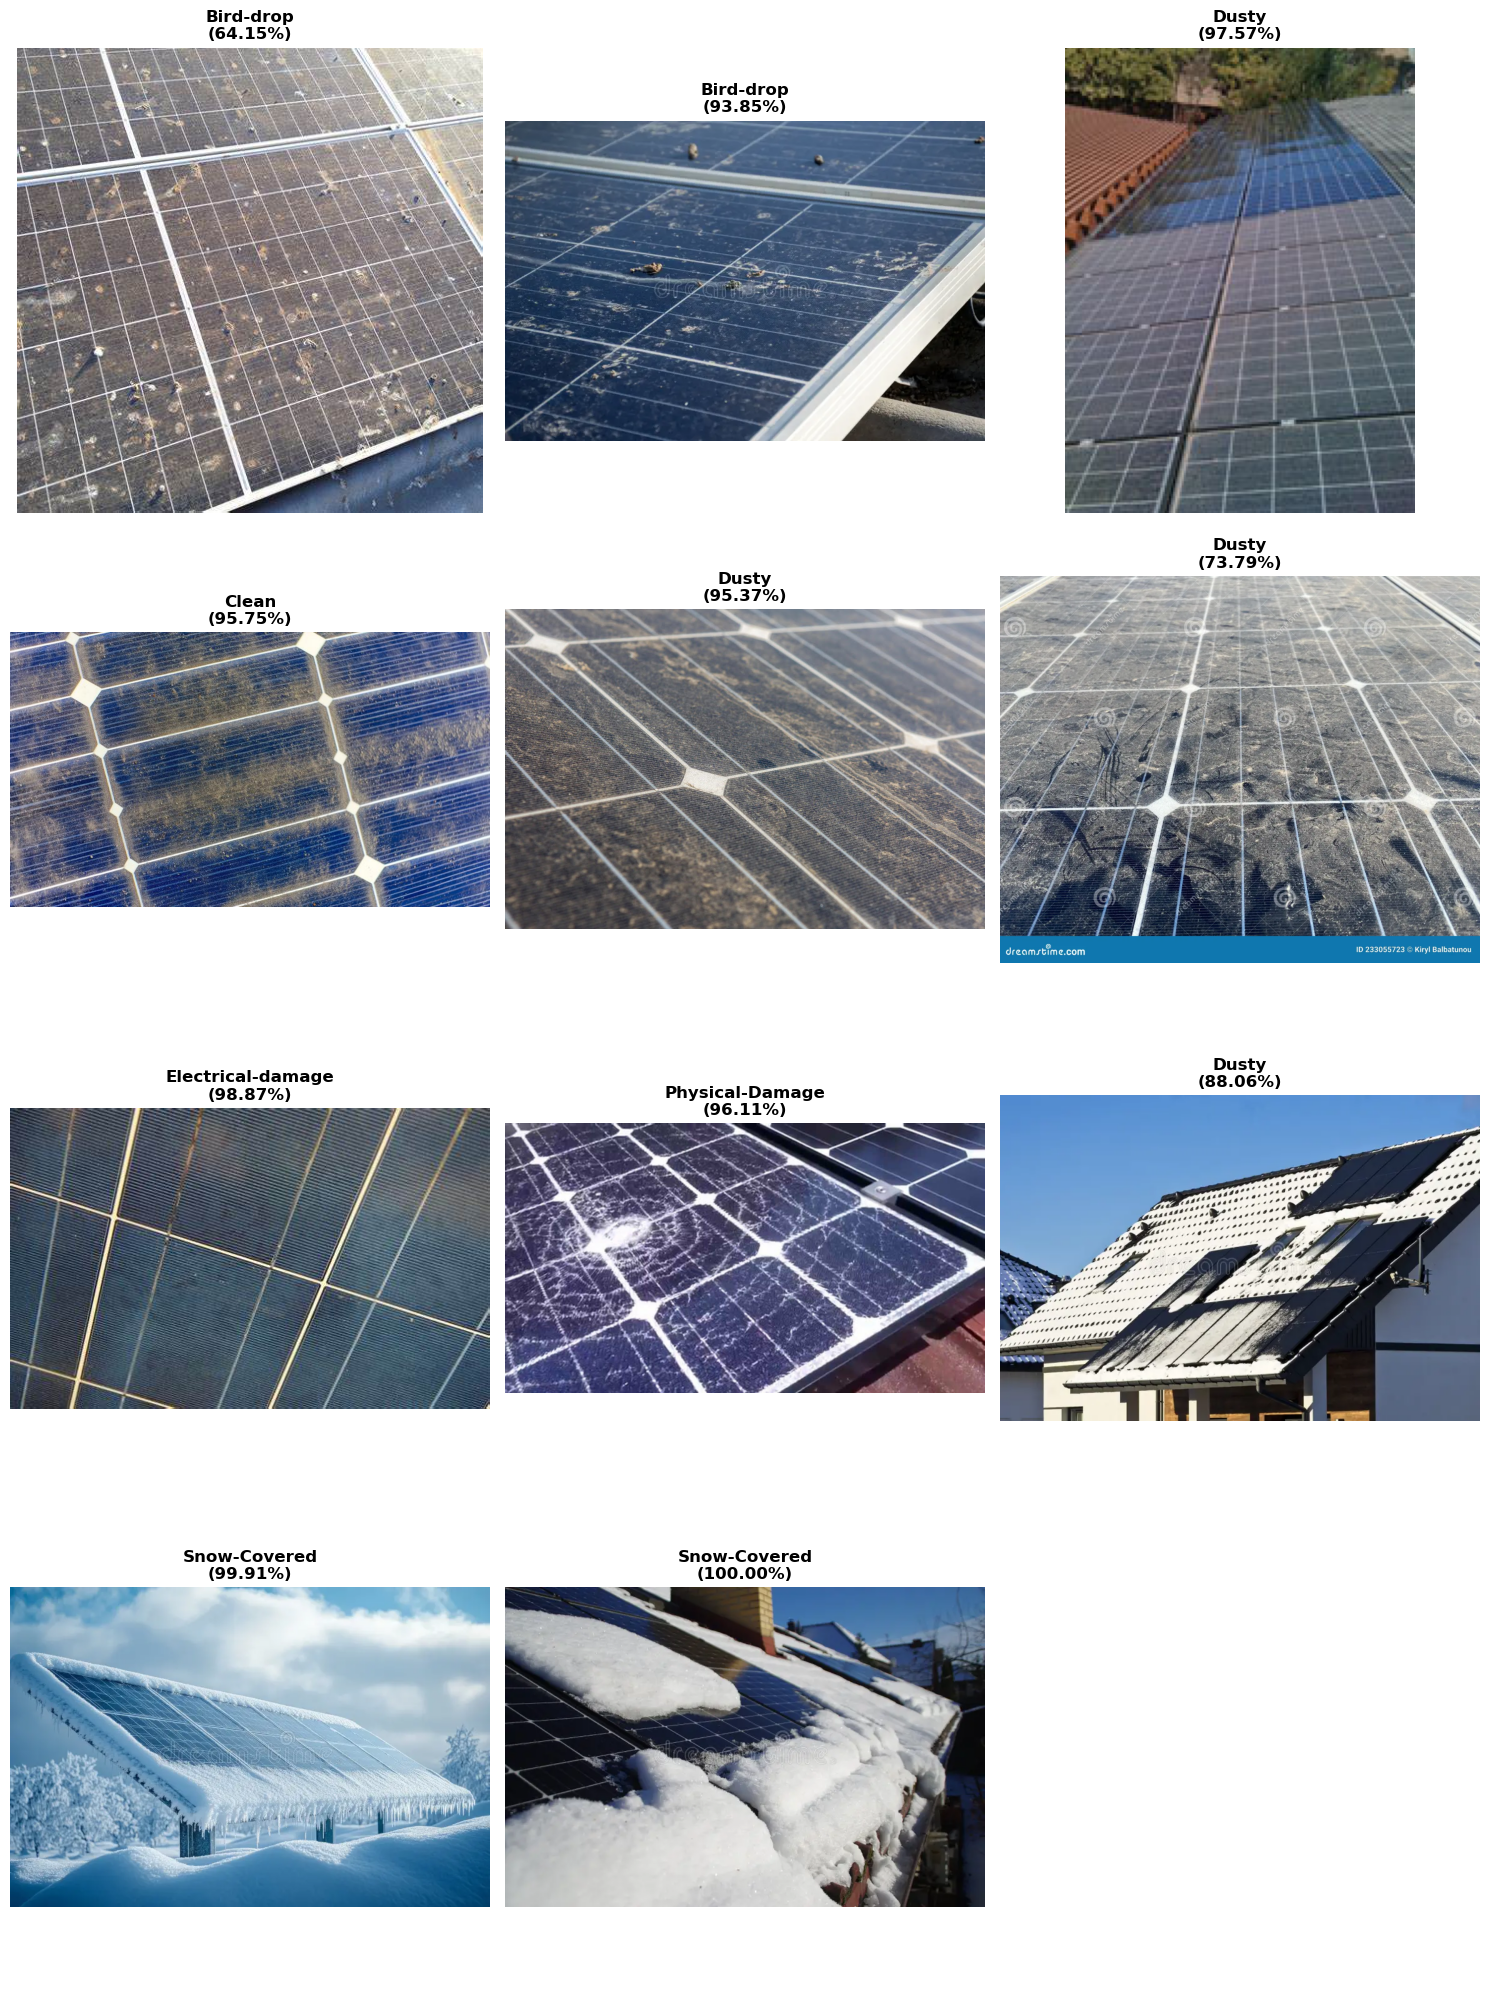

In [53]:
import os

img_dir = '../Test'

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(valid_extensions)]

print(f"Found {len(image_files)} image(s) in '{img_dir}'\n")

cols = 3
rows = (len(image_files) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten()

for idx, img_name in enumerate(image_files):
    img_path = os.path.join(img_dir, img_name)

    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        print(f"Could not read: {img_name}")
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (img_wdt, img_hgt))
    img_array = np.expand_dims(img_resized, axis=0).astype('float32')
    img_preprocessed = preprocess_input(img_array)

    predictions = model.predict(img_preprocessed, verbose=0)
    predicted_idx = np.argmax(predictions[0])
    predicted_class = class_names[predicted_idx]
    confidence = predictions[0][predicted_idx] * 100

    axes[idx].imshow(img_rgb)
    axes[idx].set_title(f"{predicted_class}\n({confidence:.2f}%)", fontsize=12, fontweight='bold')
    axes[idx].axis('off')

    print(f"[{idx+1}/{len(image_files)}] {img_name} -> {predicted_class} ({confidence:.2f}%)")

for i in range(len(image_files), len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()
